In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from sklearn.metrics import roc_auc_score

In [ ]:
ROOT = Path.cwd().parent
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
FEATURE_COLS = [f"COL{i}" for i in range(1, 159)]
SPLIT_BY_MONTH = {**dict.fromkeys(range(1, 10), "train"), 10: "val", 11: "test", 12: "test"}

In [ ]:
def savefig(fig: plt.Figure, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.png", dpi=600, bbox_inches="tight")

In [ ]:
apps = pl.read_parquet(PROCESSED_DIR / "applications.parquet")
labels = pl.read_parquet(PROCESSED_DIR / "labels.parquet")

In [ ]:
current = (
    apps.filter(pl.col("NUM") == 0)
    .drop("NUM")
    .join(labels, on="IDX", how="inner")
    .join(apps.group_by("IDX").agg(n_prev=pl.len() - 1), on="IDX", how="inner")
    .with_columns(
        month=pl.col("ts").dt.month(),
        weekday=pl.col("ts").dt.weekday(),
        hour=pl.col("ts").dt.hour(),
    )
    .with_columns(split=pl.col("month").replace_strict(SPLIT_BY_MONTH))
)

current

IDX,ts,COL1,COL2,COL3,COL4,COL5,COL6,COL7,COL8,COL9,COL10,COL11,COL12,COL13,COL14,COL15,COL16,COL17,COL18,COL19,COL20,COL21,COL22,COL23,COL24,COL25,COL26,COL27,COL28,COL29,COL30,COL31,COL32,COL33,COL34,COL35,…,COL128,COL129,COL130,COL131,COL132,COL133,COL134,COL135,COL136,COL137,COL138,COL139,COL140,COL141,COL142,COL143,COL144,COL145,COL146,COL147,COL148,COL149,COL150,COL151,COL152,COL153,COL154,COL155,COL156,COL157,COL158,TRG,n_prev,month,weekday,hour,split
i64,datetime[μs],u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,…,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u32,i8,i8,i8,str
149244095,2018-03-02 05:19:02,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,7,3,5,5,"""train"""
163565495,2018-08-02 04:27:07,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,8,4,4,"""train"""
149754110,2018-03-07 17:27:11,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,3,3,17,"""train"""
161205120,2018-07-11 17:13:30,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9,7,3,17,"""train"""
171680765,2018-10-12 14:27:08,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,10,5,14,"""val"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
154670080,2018-05-04 21:19:33,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,5,5,21,"""train"""
173300605,2018-10-26 13:54:24,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,9,10,5,13,"""val"""
161290005,2018-07-12 14:11:08,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,7,4,14,"""train"""


In [ ]:
history = (
    apps.filter(pl.col("NUM") > 0)
    .join(current.select("IDX", "split", cur_ts=pl.col("ts")), on="IDX", how="inner")
    .with_columns(
        days_before_current=(pl.col("cur_ts") - pl.col("ts")).dt.total_days(fractional=True)
    )
    .drop("cur_ts")
)

history

IDX,NUM,ts,COL1,COL2,COL3,COL4,COL5,COL6,COL7,COL8,COL9,COL10,COL11,COL12,COL13,COL14,COL15,COL16,COL17,COL18,COL19,COL20,COL21,COL22,COL23,COL24,COL25,COL26,COL27,COL28,COL29,COL30,COL31,COL32,COL33,COL34,…,COL124,COL125,COL126,COL127,COL128,COL129,COL130,COL131,COL132,COL133,COL134,COL135,COL136,COL137,COL138,COL139,COL140,COL141,COL142,COL143,COL144,COL145,COL146,COL147,COL148,COL149,COL150,COL151,COL152,COL153,COL154,COL155,COL156,COL157,COL158,split,days_before_current
i64,u8,datetime[μs],u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,…,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,u8,str,f64
144535365,1,2017-12-30 20:07:48,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,…,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,"""train""",1.208391
144535365,2,2017-11-30 11:10:57,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,…,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,"""train""",31.581204
144535380,1,2016-06-20 11:12:33,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,…,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,"""train""",559.623345
144535380,2,2016-05-07 10:55:07,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,…,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,"""train""",603.635451
144535380,3,2014-06-25 17:23:07,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,…,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,"""train""",1285.366007
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
182301280,1,2018-09-08 14:20:05,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,…,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,"""test""",114.397581
182301280,2,2018-06-04 15:01:19,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,…,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,"""test""",210.368947
182301280,3,2017-11-08 13:59:19,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,…,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,"""test""",418.412002


In [ ]:
assert current.height == labels.height and current["TRG"].null_count() == 0
assert current.height + history.height == apps.height
assert history["days_before_current"].min() >= 0

eda = current.filter(pl.col("split") != "test")
current.estimated_size("mb"), history.estimated_size("mb")

(141.34947967529297, 768.6690330505371)

In [ ]:
current.group_by("split").agg(
    n=pl.len(),
    share=pl.len() / current.height,
    first=pl.col("ts").min(),
    last=pl.col("ts").max(),
    target_rate=pl.col("TRG").mean(),
).sort("first")

split,n,share,first,last,target_rate
str,u32,f64,datetime[μs],datetime[μs],f64
"""train""",564718,0.711052,2018-01-01 01:07:53,2018-09-30 23:55:59,0.052695
"""val""",70432,0.088683,2018-10-01 00:00:00,2018-10-31 23:59:41,0.051085
"""test""",159051,0.200265,2018-11-01 00:00:00,2018-12-31 23:52:36,0.053172


In [ ]:
BASE_RATE = eda["TRG"].mean()


def target_rate(df: pl.DataFrame, by: str) -> pl.DataFrame:
    return (
        df.group_by(by)
        .agg(
            n=pl.len(),
            rate=pl.col("TRG").mean(),
        )
        .with_columns(se=(pl.col("rate") * (1 - pl.col("rate")) / pl.col("n")).sqrt())
        .sort(by)
    )

In [ ]:
def plot_rate(stats: pl.DataFrame, by: str, title: str) -> plt.Figure:
    fig, ax = plt.subplots(figsize=(9, 4))
    x = stats[by].to_numpy()
    ax.bar(x, stats["n"].to_numpy(), color="lightgray")
    ax.set_xlabel(by)
    ax.set_ylabel("applications")

    ax2 = ax.twinx()
    ax2.errorbar(
        x,
        stats["rate"].to_numpy(),
        yerr=1.96 * stats["se"].to_numpy(),
        marker="o",
        color="C3",
        capsize=3,
    )
    ax2.axhline(BASE_RATE, color="C3", ls="--", alpha=0.5)
    ax2.set_ylabel("target rate")
    ax2.set_ylim(0, 1)
    ax2.set_title(title)
    return fig

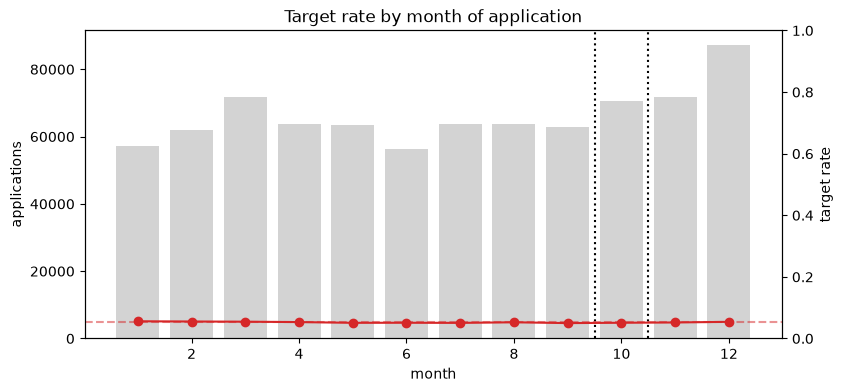

In [ ]:
fig = plot_rate(target_rate(current, "month"), "month", "Target rate by month of application")
for border in (9.5, 10.5):
    fig.axes[0].axvline(border, color="black", ls=":")

savefig(fig, "target_by_month")

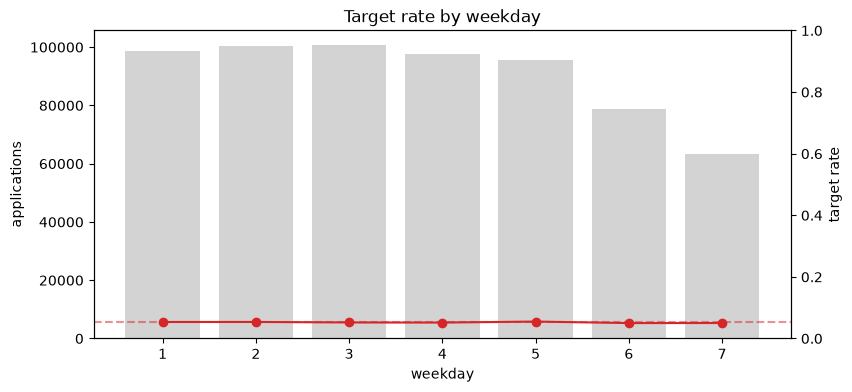

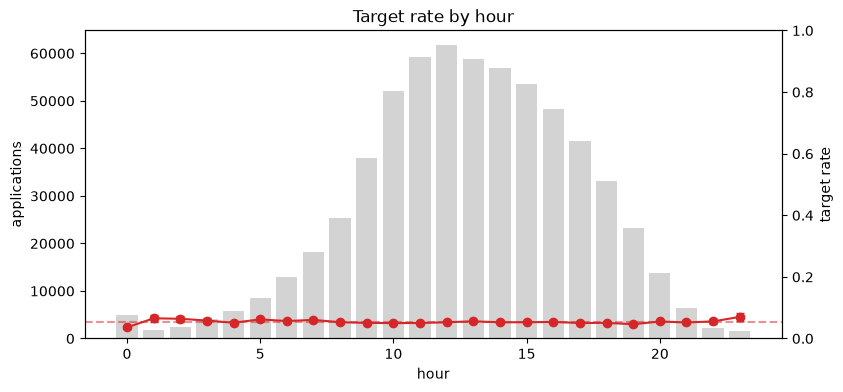

In [ ]:
for by in ("weekday", "hour"):
    fig = plot_rate(target_rate(eda, by), by, f"Target rate by {by}")
    savefig(fig, f"target_by_{by}")

In [ ]:
spearman = current.select(pl.corr("IDX", pl.col("ts").cast(pl.Int64), method="spearman")).item()

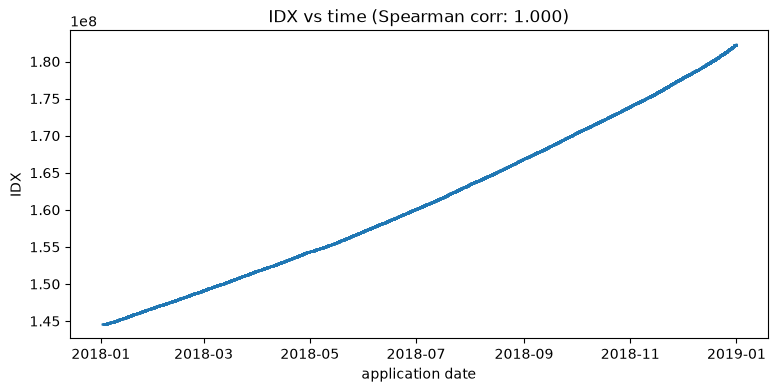

In [ ]:
sample = current.sample(20_000, seed=0)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(sample["ts"].to_numpy(), sample["IDX"].to_numpy(), s=1, alpha=0.3)
ax.set(
    xlabel="application date", ylabel="IDX", title=f"IDX vs time (Spearman corr: {spearman:.3f})"
)
savefig(fig, "idx_vs_time")

In [ ]:
y = eda["TRG"].to_numpy()
auc = {
    "IDX": roc_auc_score(y, eda["IDX"].to_numpy()),
    "ts": roc_auc_score(y, eda["ts"].cast(pl.Int64).to_numpy()),
    "IDX with month (mean)": np.mean(
        [roc_auc_score(g["TRG"], g["IDX"]) for _, g in eda.group_by("month")]
    ),
}
auc

{'IDX': 0.4902051389051298,
 'ts': 0.4902051428655868,
 'IDX with month (mean)': np.float64(0.4979653512658085)}

In [ ]:
row_key = pl.struct("ts", *FEATURE_COLS).hash()

as_current = current.select(
    key=row_key,
    erlier_idx=pl.col("IDX"),
    erlier_split=pl.col("split"),
    earlier_trg=pl.col("TRG"),
)

in_history = history.select(
    key=row_key,
    later_idx=pl.col("IDX"),
    later_split=pl.col("split"),
    num=pl.col("NUM"),
)

repeats = in_history.join(as_current, on="key", how="inner")

n_rep = repeats["erlier_idx"].n_unique()
print(f"current apps found in other clietns history: {n_rep:_} ({n_rep / current.height:.2%})")

current apps found in other clietns history: 0 (0.00%)


In [ ]:
WINDOW = (1, 7, 30, 90, 180, 365)

hist_feats = history.group_by("IDX").agg(
    *[(pl.col("days_before_current") <= w).sum().alias(f"n_prev_{w}d") for w in WINDOW],
    days_since_prev=pl.col("days_before_current").min(),
    days_since_oldest=pl.col("days_before_current").max(),
)

current = current.join(hist_feats, on="IDX", how="inner")
eda = current.filter(pl.col("split") != "test")
assert current.height == labels.height

In [ ]:
def add_bins(df: pl.DataFrame, col: str, breaks: list[int], name: str) -> pl.DataFrame:
    return df.with_columns(pl.sum_horizontal([pl.col(col) > b for b in breaks]).alias(name))

In [ ]:
def plot_binned(
    df: pl.DataFrame, col: str, breaks: list[int], labels: list[str], title: str
) -> plt.Figure:
    stats = target_rate(add_bins(df, col, breaks, "bin"), "bin")
    fig = plot_rate(stats, "bin", title)
    fig.axes[0].set_xticks(stats["bin"].to_numpy(), [labels[i] for i in stats["bin"]])
    fig.axes[0].set_xlabel(col)
    return fig

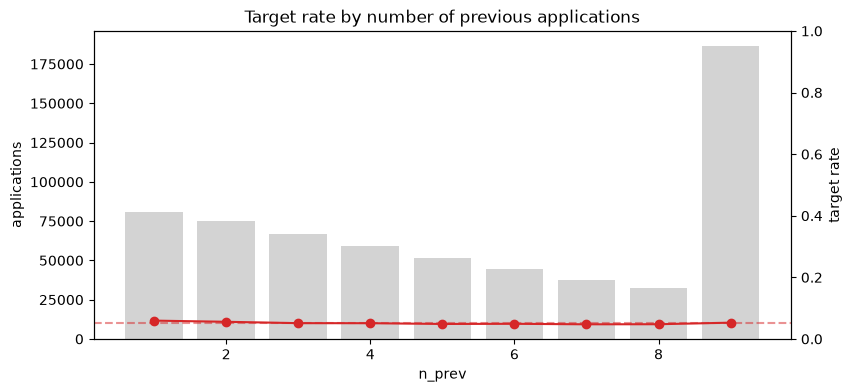

In [ ]:
fig = plot_rate(
    target_rate(eda, "n_prev"), "n_prev", "Target rate by number of previous applications"
)
savefig(fig, "target_by_n_prev")

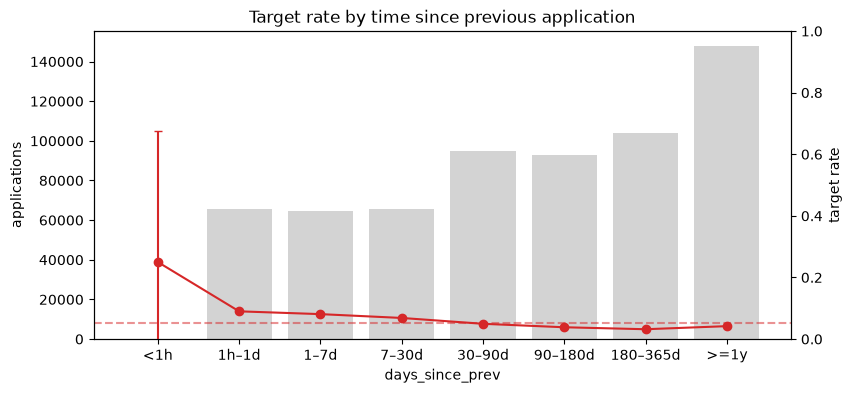

In [ ]:
fig = plot_binned(
    eda,
    "days_since_prev",
    breaks=[1 / 24, 1, 7, 30, 90, 180, 365],
    labels=["<1h", "1h–1d", "1–7d", "7–30d", "30–90d", "90–180d", "180–365d", ">=1y"],
    title="Target rate by time since previous application",
)
savefig(fig, "target_by_days_since_prev")

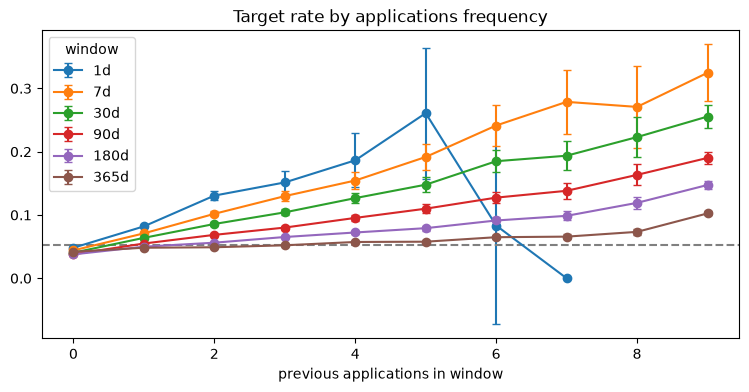

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
for w in WINDOW:
    stats = target_rate(eda.with_columns(pl.col(f"n_prev_{w}d").alias("cnt")), "cnt")
    ax.errorbar(
        stats["cnt"].to_numpy(),
        stats["rate"].to_numpy(),
        yerr=1.96 * stats["se"].to_numpy(),
        marker="o",
        capsize=3,
        label=f"{w}d",
    )

ax.axhline(BASE_RATE, color="gray", ls="--")
ax.set(
    xlabel="previous applications in window",
    label="target rate",
    title="Target rate by applications frequency",
)
ax.legend(title="window")
savefig(fig, "target_by_app_frequency")

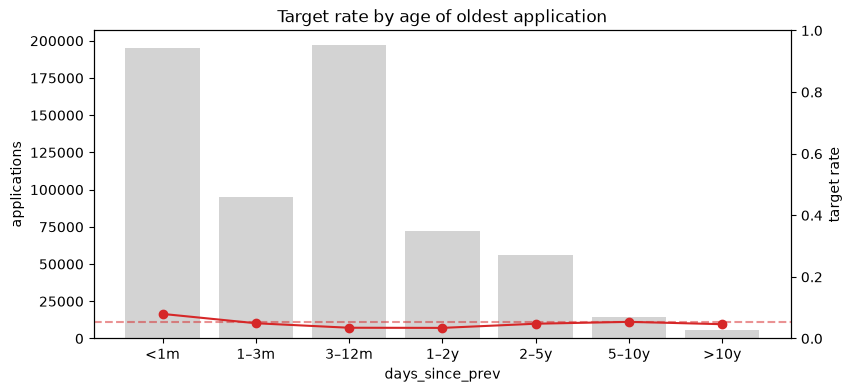

In [ ]:
fig = plot_binned(
    eda,
    "days_since_prev",
    breaks=[30, 90, 365, 730, 1825, 3650],
    labels=["<1m", "1–3m", "3–12m", "1–2y", "2–5y", "5–10y", ">10y"],
    title="Target rate by age of oldest application",
)
savefig(fig, "target_by_history_age")

In [ ]:
y = eda["TRG"].to_numpy()
hist_cols = ["n_prev", "days_since_prev", "days_since_oldest", *[f"n_prev_{w}d" for w in WINDOW]]
pl.DataFrame(
    {"feature": hist_cols, "auc": [roc_auc_score(y, eda[c].to_numpy()) for c in hist_cols]}
).with_columns(gini=(2 * pl.col("auc") - 1).abs()).sort("gini", descending=True)

feature,auc,gini
str,f64,f64
"""n_prev_90d""",0.602791,0.205582
"""n_prev_30d""",0.59596,0.19192
"""days_since_oldest""",0.404099,0.191802
"""days_since_prev""",0.405331,0.189338
"""n_prev_180d""",0.591112,0.182223
"""n_prev_7d""",0.572657,0.145313
"""n_prev_365d""",0.558229,0.116458
"""n_prev_1d""",0.539527,0.079053
"""n_prev""",0.489477,0.021046


constant: ['COL2', 'COL7', 'COL17', 'COL21', 'COL23', 'COL24', 'COL25', 'COL26', 'COL27', 'COL35', 'COL103', 'COL104', 'COL105', 'COL106', 'COL107', 'COL108', 'COL109', 'COL110', 'COL111', 'COL112', 'COL113', 'COL114', 'COL115', 'COL116', 'COL117', 'COL118', 'COL119', 'COL120', 'COL121', 'COL122', 'COL123', 'COL124', 'COL125', 'COL126', 'COL127', 'COL128', 'COL129', 'COL130', 'COL131', 'COL132', 'COL133', 'COL134', 'COL135', 'COL136', 'COL137', 'COL138', 'COL139', 'COL140', 'COL141', 'COL142', 'COL143', 'COL144', 'COL145', 'COL146', 'COL147', 'COL148', 'COL149', 'COL150', 'COL151', 'COL152', 'COL153', 'COL154', 'COL155', 'COL156', 'COL157', 'COL158']
near-constant: []


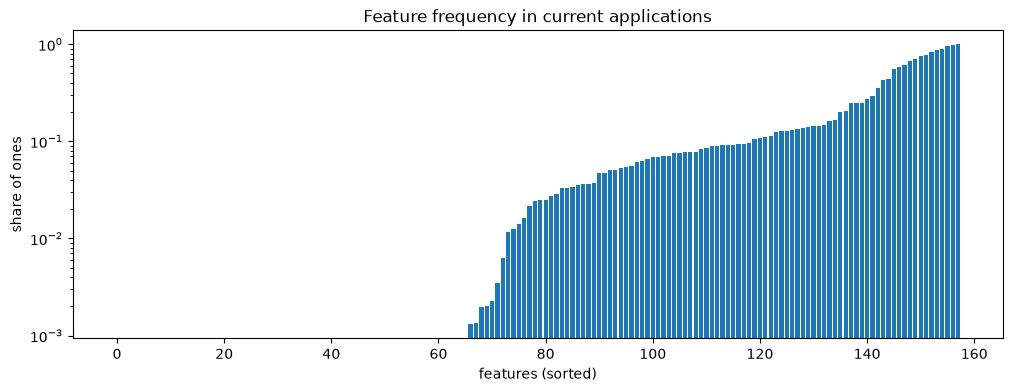

In [ ]:
freq = (
    current.select(pl.col(FEATURE_COLS).mean())
    .unpivot(variable_name="feature", value_name="freq")
    .sort("freq")
)

RARE = 1e-3

print("constant:", freq.filter(pl.col("freq").is_in([0.0, 0.1]))["feature"].to_list())

near_constant = freq.filter(
    (pl.col("freq") > 0)
    & (pl.col("freq") < 1)
    & ((pl.col("freq") < RARE) | (pl.col("freq") > 1 - RARE))
)
print("near-constant:", near_constant["feature"].to_list())

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(freq)), freq["freq"].to_numpy())
ax.set(
    yscale="log",
    xlabel="features (sorted)",
    ylabel="share of ones",
    title="Feature frequency in current applications",
)
savefig(fig, "feature_frequency")

In [ ]:
import hashlib

X_cur = current.select(FEATURE_COLS).to_numpy()


def digest(col: np.ndarray) -> bytes:
    return hashlib.blake2b(col.tobytes(), digest_size=16).digest()


seen: dict[bytes, str] = {}
pairs = []
for j, name in enumerate(FEATURE_COLS):
    col = X_cur[:, j]
    if col.min() == col.max():
        continue
    for key, kind in ((digest(col), "equal"), (digest(1 - col), "complement")):
        if key in seen:
            pairs.append((seen[key], name, kind))
    seen.setdefault(digest(col), name)

pairs

[]

In [ ]:
Xe = eda.select(FEATURE_COLS).to_numpy().astype(np.float32)
y = eda["TRG"].to_numpy().astype(np.float32)

n, bad = len(y), y.sum()
good = n - bad
n1 = Xe.sum(axis=0)
bad1 = Xe.T @ y
good1 = n1 - bad1
bad0, good0 = bad - bad1, good - good1

In [ ]:
eps = 0.5
dist = lambda k, total: (k + eps) / (total + 2 * eps)  # noqa: E731
iv = sum(
    (dist(g, good) - dist(b, bad)) * np.log(dist(g, good) / dist(b, bad))
    for g, b in ((good1, bad1), (good0, bad0))
)
tpr, fpr = bad1 / bad, good1 / good

In [ ]:
univariate = (
    pl.DataFrame(
        {
            "feature": FEATURE_COLS,
            "freq": n1 / n,
            "rate1": np.where(n1 > 0, bad1 / np.maximum(n1, 1), np.nan),
            "rate0": bad0 / (n - n1),
            "iv": iv,
            "gini": np.abs(tpr - fpr),
        }
    )
    .with_columns(
        lift=pl.col("rate1") / BASE_RATE,
        risky=pl.col("rate1") > BASE_RATE,
    )
    .sort("iv", descending=True)
)
univariate.head(10)

feature,freq,rate1,rate0,iv,gini,lift,risky
str,f32,f32,f32,f32,f32,f32,bool
"""COL16""",0.060971,0.091102,0.050011,0.030458,0.04728,1.734716,true
"""COL18""",0.031075,0.016619,0.053668,0.027092,0.022419,0.316443,false
"""COL30""",0.028219,0.018301,0.05351,0.021484,0.019404,0.34847,false
"""COL12""",0.052704,0.08702,0.050597,0.021258,0.036546,1.656999,true
"""COL40""",0.025986,0.018055,0.053436,0.020143,0.017997,0.343798,false
"""COL37""",0.134285,0.037167,0.054898,0.016918,0.041425,0.707715,false
"""COL94""",0.432114,0.059394,0.047284,0.014381,0.05972,1.130947,true
"""COL96""",0.777958,0.049233,0.064022,0.014293,0.05134,0.937472,false
"""COL87""",0.021741,0.098486,0.051495,0.01406,0.020086,1.875336,true


useless,weak,medium,strong
u32,u32,u32,u32
153,5,0,0


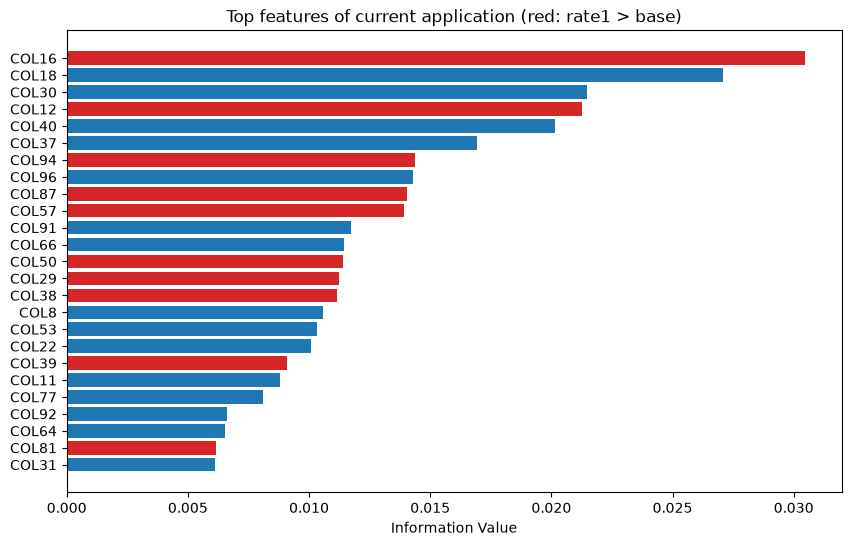

In [ ]:
top = univariate.head(25)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    top["feature"].to_numpy()[::-1],
    top["iv"].to_numpy()[::-1],
    color=np.where(top["risky"].to_numpy()[::-1], "C3", "C0"),
)
ax.set(xlabel="Information Value", title="Top features of current application (red: rate1 > base)")
savefig(fig, "top_features_iv")

univariate.select(
    useless=(pl.col("iv") < 0.02).sum(),
    weak=pl.col("iv").is_between(0.02, 0.1).sum(),
    medium=pl.col("iv").is_between(0.1, 0.3).sum(),
    strong=(pl.col("iv") > 0.3).sum(),
)

0.48381045676525086

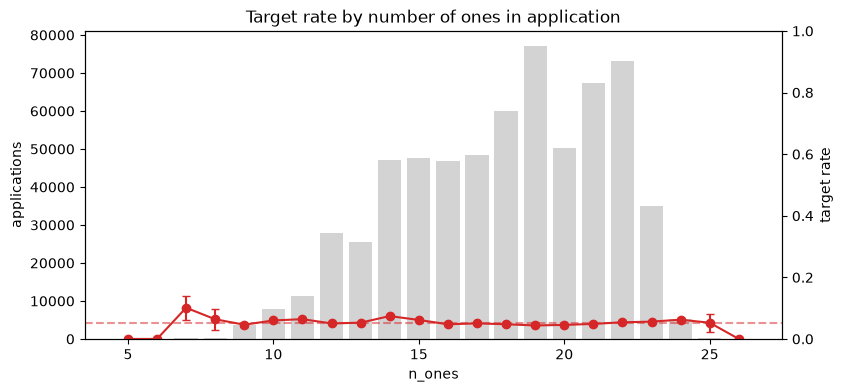

In [ ]:
current = current.with_columns(n_ones=pl.sum_horizontal(pl.col(FEATURE_COLS).cast(pl.UInt16)))
eda = current.filter(pl.col("split") != "test")

fig = plot_rate(
    target_rate(eda, "n_ones"), "n_ones", "Target rate by number of ones in application"
)
savefig(fig, "target_by_n_ones")
roc_auc_score(eda["TRG"], eda["n_ones"])

In [ ]:
def univariate_stats(X: np.ndarray, y: np.ndarray, names: list[str]) -> pl.DataFrame:
    X = X.astype(np.float32)
    y = y.astype(np.float32)
    n, bad = len(y), y.sum()
    good = n - bad
    n1 = X.sum(axis=0)
    bad1 = X.T @ y
    good1 = n1 - bad1
    bad0, good0 = bad - bad1, good - good1

    eps = 0.5

    def dist(k, total):
        return (k + eps) / (total + 2 * eps)

    iv = sum(
        (dist(g, good) - dist(b, bad)) * np.log(dist(g, good) / dist(b, bad))
        for g, b in ((good1, bad1), (good0, bad0))
    )
    return (
        pl.DataFrame(
            {
                "feature": names,
                "freq": n1 / n,
                "rate1": np.where(n1 > 0, bad1 / np.maximum(n1, 1), np.nan),
                "iv": iv,
                "gini": np.abs(bad1 / bad - good1 / good),
            }
        )
        .with_columns(lift=pl.col("rate1") / BASE_RATE)
        .sort("iv", descending=True)
    )

In [ ]:
def iv_summary(stats: pl.DataFrame) -> pl.DataFrame:
    iv = pl.col("iv")
    return stats.select(
        useless=(iv < 0.02).sum(),
        weak=((iv >= 0.02) & (iv < 0.1)).sum(),
        medium=((iv >= 0.1) & (iv < 0.3)).sum(),
        strong=(iv >= 0.3).sum(),
    )

In [ ]:
hist_freq = history.select(pl.col(FEATURE_COLS).mean()).unpivot(
    variable_name="feature", value_name="hist_freq"
)

freq_cmp = (
    freq.join(hist_freq, on="feature")
    .with_columns(col_num=pl.col("feature").str.slice(3).cast(pl.Int32))
    .sort("col_num")
)

n_const,n_filled_in_history,min_hist_freq,max_hist_freq
u32,u32,f64,f64
66,61,0.0,0.739286


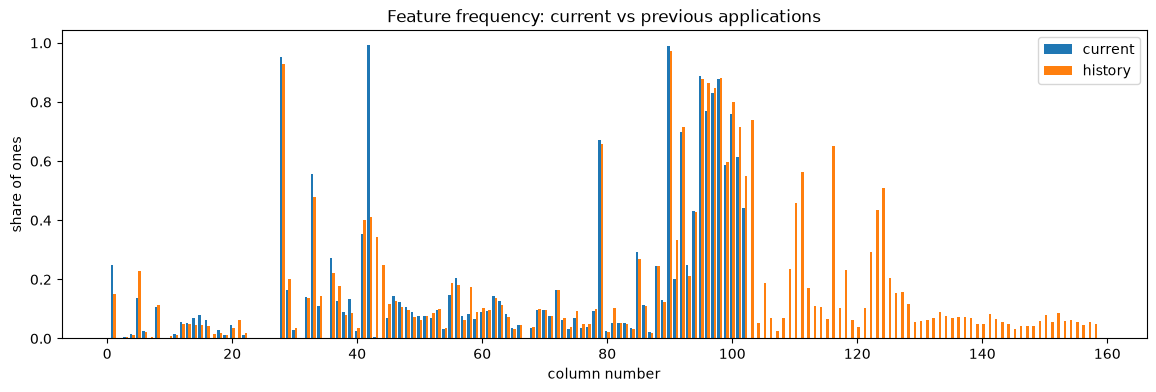

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4))
x = freq_cmp["col_num"].to_numpy()
ax.bar(x - 0.2, freq_cmp["freq"].to_numpy(), width=0.4, label="current")
ax.bar(x + 0.2, freq_cmp["hist_freq"].to_numpy(), width=0.4, label="history")
ax.set(
    xlabel="column number",
    ylabel="share of ones",
    title="Feature frequency: current vs previous applications",
)
ax.legend()
savefig(fig, "freq_current_vs_history")


freq_cmp.filter(pl.col("freq").is_in([0.0, 1.0])).select(
    n_const=pl.len(),
    n_filled_in_history=((pl.col("hist_freq") > 0) & (pl.col("hist_freq") < 1)).sum(),
    min_hist_freq=pl.col("hist_freq").min(),
    max_hist_freq=pl.col("hist_freq").max(),
)

In [ ]:
hist_any = history.group_by("IDX").agg(pl.col(FEATURE_COLS).max())  # 1 if in any previous app
hist_last = history.filter(pl.col("NUM") == 1).select(
    "IDX", *FEATURE_COLS
)  # most recent previous app

eda_ids = eda.select("IDX", "TRG")
stats = {"current": univariate_stats(Xe, y, FEATURE_COLS)}
for name, table in (("any_prev", hist_any), ("last_prev", hist_last)):
    df = eda_ids.join(table, on="IDX", how="inner")
    stats[name] = univariate_stats(
        df.select(FEATURE_COLS).to_numpy(), df["TRG"].to_numpy(), FEATURE_COLS
    )

pl.concat([iv_summary(s).with_columns(source=pl.lit(k)) for k, s in stats.items()])

useless,weak,medium,strong,source
u32,u32,u32,u32,str
153,5,0,0,"""current"""
123,34,1,0,"""any_prev"""
148,8,2,0,"""last_prev"""


In [ ]:
stats["any_prev"].head(10)

feature,freq,rate1,iv,gini,lift
str,f32,f32,f32,f32,f32
"""COL43""",0.759704,0.037901,0.228222,0.223156,0.721685
"""COL129""",0.204383,0.085492,0.095833,0.135444,1.627892
"""COL103""",0.874612,0.046325,0.084765,0.108832,0.8821
"""COL44""",0.599589,0.063349,0.076401,0.130524,1.206257
"""COL130""",0.189569,0.078892,0.056945,0.100484,1.502228
"""COL40""",0.121165,0.025546,0.053896,0.065674,0.486443
"""COL117""",0.276138,0.035042,0.05327,0.096976,0.667256
"""COL20""",0.12993,0.027882,0.046961,0.064325,0.530925
"""COL39""",0.277511,0.069261,0.040344,0.093385,1.318835


In [ ]:
stats["last_prev"].head(10)

feature,freq,rate1,iv,gini,lift
str,f32,f32,f32,f32,f32
"""COL43""",0.282023,0.028125,0.114396,0.138246,0.535549
"""COL44""",0.154408,0.09492,0.105977,0.131583,1.807425
"""COL129""",0.204383,0.085492,0.095833,0.135444,1.627892
"""COL103""",0.818632,0.046143,0.063326,0.104868,0.878626
"""COL1""",0.174965,0.071673,0.028041,0.06736,1.364774
"""COL37""",0.216396,0.039238,0.021751,0.057749,0.747149
"""COL18""",0.027562,0.018051,0.021397,0.019091,0.343718
"""COL21""",0.097424,0.032564,0.021129,0.039067,0.620061
"""COL16""",0.044303,0.089698,0.020224,0.033104,1.707981
